
# Isolation Forest for Anomaly Detection
## A Visual & Conceptual Deep Dive

**Isolation Forest** is an unsupervised learning algorithm that identifies anomalies by isolating outliers in the data.

### Core Idea:
- **Normal points** are hard to isolate; they require many splits to be separated from the rest.
- **Anomalies** are easy to isolate; they require very few splits.
- The algorithm builds an ensemble of random trees (Isolation Trees). The *path length* (number of splits) required to isolate a point is averaged across all trees. Shorter paths = higher chance of being an anomaly.

### In this Notebook:
1. **Generate Synthetic Data**: Create a clear dataset with clusters and random outliers.
2. **Visualize Data**: See the "Normal" vs "Outlier" distribution.
3. **Train Isolation Forest**: Fit the model and understand its parameters.
4. **Visualize Decision Boundaries**: See exactly where the model draws the line.
5. **Score Analysis**: Understand `decision_function` and anomaly scores.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Set visual style
sns.set(style="whitegrid")
%matplotlib inline

print("Libraries loaded successfully!")


Libraries loaded successfully!


Data Shape: (300, 2)
Normal points: 255, Outliers (Synthetic): 45


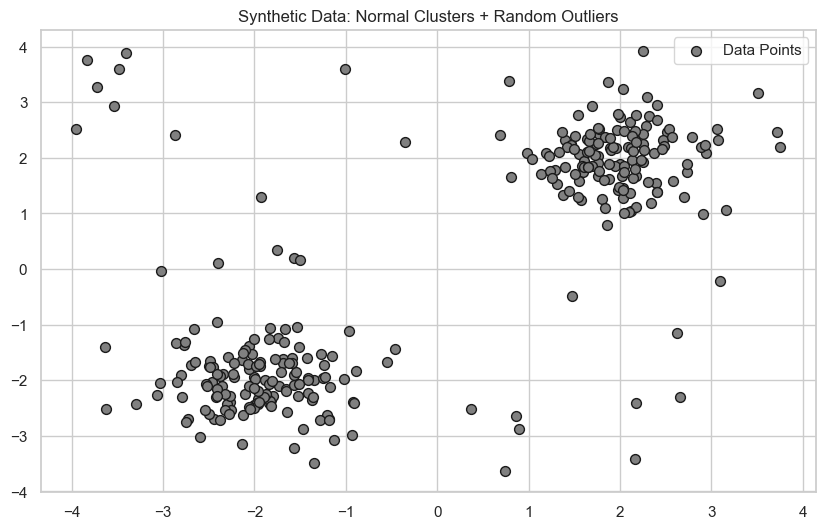

In [2]:

# 1. Generate Synthetic Data
# We create two distinct clusters (blobs) to represent 'Normal' behavior.
n_samples = 300
outliers_fraction = 0.15
n_outliers = int(outliers_fraction * n_samples)
n_inliers = n_samples - n_outliers

# Generate inliers (dense clusters)
X_inliers, _ = make_blobs(n_samples=n_inliers, centers=[[2, 2], [-2, -2]], cluster_std=0.5, random_state=42)

# Generate outliers (random uniform noise scattered across the space)
rng = np.random.RandomState(42)
X_outliers = rng.uniform(low=-4, high=4, size=(n_outliers, 2))

# Combine them
X = np.concatenate([X_inliers, X_outliers], axis=0)

print(f"Data Shape: {X.shape}")
print(f"Normal points: {n_inliers}, Outliers (Synthetic): {n_outliers}")

# Plot the raw data
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c='gray', edgecolor='k', s=50, label='Data Points')
plt.title("Synthetic Data: Normal Clusters + Random Outliers")
plt.legend()
plt.show()



## Training the Isolation Forest

Key Parameters:
- `n_estimators`: The number of trees in the ensemble (default 100). More trees = more stable scores.
- `contamination`: The expected proportion of outliers in the dataset. Used to define the threshold for the decision function. 
    - If set to 'auto', the threshold is determined as in the original paper.
    - If detailed domain knowledge is available, setting this helps the model make binary predictions (1 vs -1).
- `max_samples`: The number of samples to draw from X to train each base estimator.


In [3]:

# Initialize Isolation Forest
# We know we added approx 15% outliers, so we can suggest that to the model
clf = IsolationForest(n_estimators=100, 
                      contamination=outliers_fraction, 
                      random_state=42, 
                      max_samples='auto')

# Fit the model
clf.fit(X)
print("Isolation Forest Fitted.")


Isolation Forest Fitted.


In [4]:

# Predict labels: 1 for inliers, -1 for outliers
y_pred = clf.predict(X)

# Separate the points based on prediction for visualization
X_normal = X[y_pred == 1]
X_anomaly = X[y_pred == -1]

print(f"Predicted Normal: {len(X_normal)}")
print(f"Predicted Anomalies: {len(X_anomaly)}")


Predicted Normal: 255
Predicted Anomalies: 45


C:\Users\Satej Raste\AppData\Local\Temp\ipykernel_3916\2779873251.py:7: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_anomaly[:, 0], X_anomaly[:, 1], c='red', s=50, edgecolor='k', marker='x', label='Predicted Anomaly')


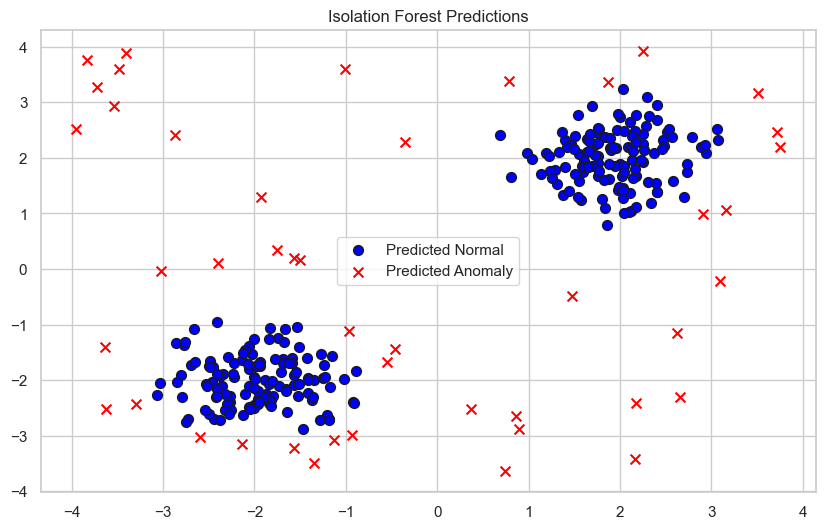

In [5]:

plt.figure(figsize=(10, 6))

# Plot Inliers
plt.scatter(X_normal[:, 0], X_normal[:, 1], c='blue', s=50, edgecolor='k', label='Predicted Normal')

# Plot Outliers
plt.scatter(X_anomaly[:, 0], X_anomaly[:, 1], c='red', s=50, edgecolor='k', marker='x', label='Predicted Anomaly')

plt.title("Isolation Forest Predictions")
plt.legend()
plt.show()



## Visualizing the Decision Boundary

We can visualize the "anomaly score" across the entire 2D space. 
- Darker regions (or specific contour lines) indicate where the model believes data is "normal".
- As we move away from these regions, the anomaly score increases (or the decision function value decreases).


C:\Users\Satej Raste\AppData\Local\Temp\ipykernel_3916\2806062781.py:17: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  b2 = plt.scatter(X_anomaly[:, 0], X_anomaly[:, 1], c='red', s=50, edgecolor='k', marker='x')


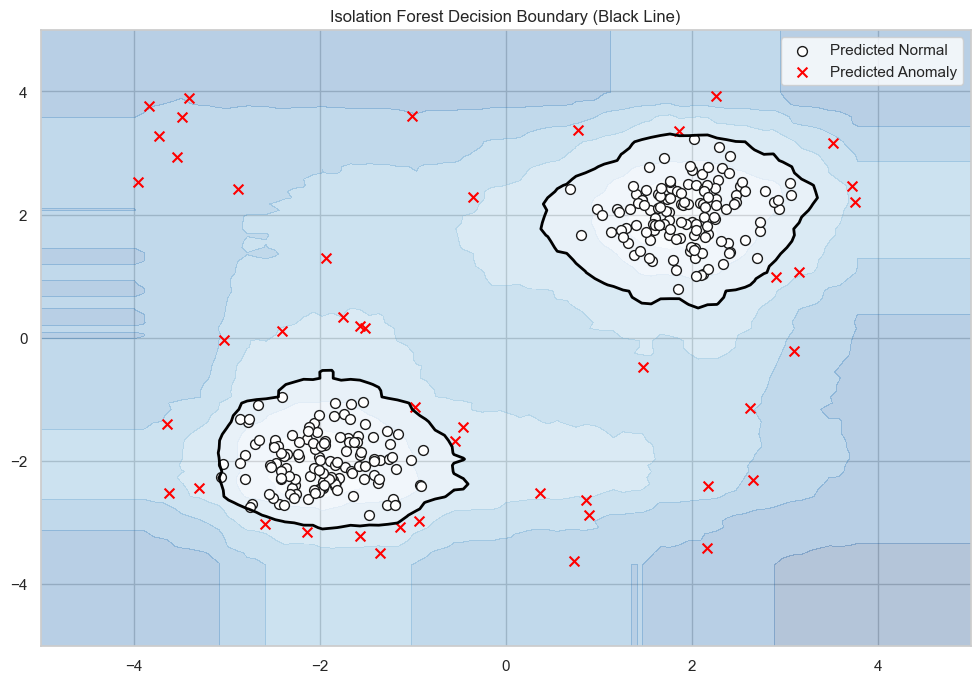

In [6]:

# Create a meshgrid to plot the decision function over the whole space
xx, yy = np.meshgrid(np.linspace(-5, 5, 100), np.linspace(-5, 5, 100))
Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(12, 8))

# Plot the contour lines of the decision function
# filled contours for background
plt.contourf(xx, yy, Z, cmap=plt.cm.Blues_r, alpha=0.3) 

# Draw the specific decision boundary (where score = 0)
plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')

# Plot the actual data points again on top
b1 = plt.scatter(X_normal[:, 0], X_normal[:, 1], c='white', s=50, edgecolor='k')
b2 = plt.scatter(X_anomaly[:, 0], X_anomaly[:, 1], c='red', s=50, edgecolor='k', marker='x')

plt.title("Isolation Forest Decision Boundary (Black Line)")
plt.legend([b1, b2], ["Predicted Normal", "Predicted Anomaly"])
plt.show()



### Understanding Scores
`decision_function(X)` returns the anomaly score.
- **Negative scores** represent outliers.
- **Positive scores** represent inliers.
The lower the score, the more abnormal.

`score_samples(X)` returns the opposite of the anomaly score defined in the paper (useful for ranking).


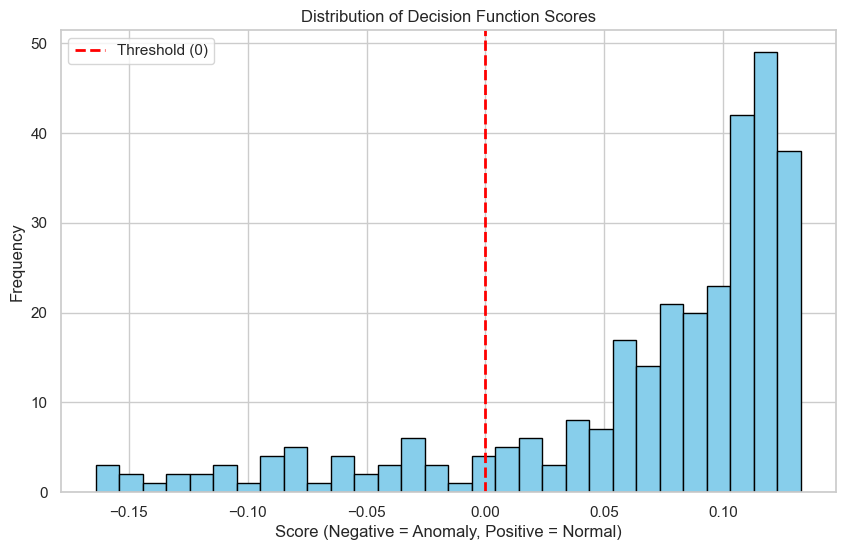

In [7]:

# Let's look at the distribution of scores
scores = clf.decision_function(X)

plt.figure(figsize=(10, 6))
plt.hist(scores, bins=30, color='skyblue', edgecolor='black')
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Threshold (0)')
plt.title("Distribution of Decision Function Scores")
plt.xlabel("Score (Negative = Anomaly, Positive = Normal)")
plt.ylabel("Frequency")
plt.legend()
plt.show()
